# Nairobi Traffic & Commute Intelligence

## 1. Data Understanding

### Objective
To examine the structure, variables, data types and completness of the dataset before performing any cleaning or analysis

In [ ]:
# Import necessary libraries
import pandas as pd
from pathlib import Path

# Define the path to the Excel file
project_dir = Path.cwd()  # Get the current working directory

if project_dir.name == "notebooks":
    project_dir = project_dir.parent 

# Locate excel dataset 
file_path = (
    project_dir
    / "data"
    / "raw"
    /"Nairobi_Commute_Raw_Times_From_Cleaned.xlsx"
)

#Load the dataset
df = pd.read_excel(file_path) 

df.head()

,observation_slot_eat,actual_request_time_eat,route_id,origin,destination,status,duration_minutes,static_duration_minutes,estimated_traffic_delay_minutes,distance_km,route_description,route_steps,error,mode,routing_preference
0,2026-11-04 06:00:00,2026-11-04 06:00:31,kiora_estate,"Kiora Estate, Kirigiti, Kiambu, Kenya","Eldama Park, Eldama Ravine Road, Westlands, Na...",ok,42.73,48.68,-5.95,21.472,Kiambu Rd,Head southwest\nPass by 1115 Residence (on the...,NaN,DRIVE,TRAFFIC_AWARE_OPTIMAL
1,2026-11-04 06:00:00,2026-11-04 06:00:32,riu_nderi,"Riu Nderi, Gikambura, Kikuyu, Kiambu County, K...","Eldama Park, Eldama Ravine Road, Westlands, Na...",ok,33.90,37.30,-3.40,21.461,A8,Head east | Turn left at Executive apartment\n...,NaN,DRIVE,TRAFFIC_AWARE_OPTIMAL
2,2026-11-04 06:00:00,2026-11-04 06:00:32,tatu_city,"Tatu City main entrance, Ruiru, Kiambu County,...","Eldama Park, Eldama Ravine Road, Westlands, Na...",ok,34.88,34.90,-0.02,25.548,Embu - Nairobi Hwy/Meru - Nairobi Hwy/Thika Rd/A2,Head west on Main St\nPass by First Ave (on th...,NaN,DRIVE,TRAFFIC_AWARE_OPTIMAL
3,2026-11-04 06:15:00,2026-11-04 06:15:31,kiora_estate,"Kiora Estate, Kirigiti, Kiambu, Kenya","Eldama Park, Eldama Ravine Road, Westlands, Na...",ok,45.90,50.55,-4.65,23.873,Kiambu Rd,Head southwest\nPass by 1115 Residence (on the...,NaN,DRIVE,TRAFFIC_AWARE_OPTIMAL
4,2026-11-04 06:15:00,2026-11-04 06:15:31,riu_nderi,"Riu Nderi, Gikambura, Kikuyu, Kiambu County, K...","Eldama Park, Eldama Ravine Road, Westlands, Na...",ok,34.15,37.30,-3.15,21.461,A8,Head east | Turn left at Executive apartment\n...,NaN,DRIVE,TRAFFIC_AWARE_OPTIMAL


In [ ]:
# Examine the structure of the dataset

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 234
Number of columns: 15


In [ ]:
# inspect the column names

print('Column names:')

for column in df.columns:
    print(column)

Column names:
observation_slot_eat
actual_request_time_eat
route_id
origin
destination
status
duration_minutes
static_duration_minutes
estimated_traffic_delay_minutes
distance_km
route_description
route_steps
error
mode
routing_preference



### 1.1 Duplicate Observation Assessment

This section investigates whether the dataset
contains repeated records that could distort
the traffic analysis.


In [ ]:
# Count duplicates rows
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


### 1.2 Dataset Structure and Data Types

In [ ]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 234 entries, 0 to 233
Data columns (total 15 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   observation_slot_eat             234 non-null    str    
 1   actual_request_time_eat          234 non-null    str    
 2   route_id                         234 non-null    str    
 3   origin                           234 non-null    str    
 4   destination                      234 non-null    str    
 5   status                           234 non-null    str    
 6   duration_minutes                 234 non-null    float64
 7   static_duration_minutes          234 non-null    float64
 8   estimated_traffic_delay_minutes  234 non-null    float64
 9   distance_km                      234 non-null    float64
 10  route_description                234 non-null    str    
 11  route_steps                      234 non-null    str    
 12  error                            

In [ ]:
# Identify repeated observation keys
duplicate_keys = df.duplicated(
    subset=["observation_slot_eat", "route_id"],
    keep=False
)

# Count and display repeated observations
print(
    "Rows with duplicate observation keys:",
    duplicate_keys.sum()
)

display(df.loc[
    duplicate_keys,
    ["observation_slot_eat", "route_id", "duration_minutes"]
])

Rows with duplicate observation keys: 0


,observation_slot_eat,route_id,duration_minutes


In [ ]:
# Checking API response status
df["status"].value_counts(dropna=False)

status
ok    234
Name: count, dtype: int64

### 1.3 Data Type Assessment and Conversion

In [ ]:
# Convert timestamp columns from strings to datetime

df["observation_slot_eat"] = pd.to_datetime(
    df["observation_slot_eat"],
    errors="coerce",
    utc=True
).dt.tz_convert("Africa/Nairobi")

df["actual_request_time_eat"] = pd.to_datetime(
    df["actual_request_time_eat"],
    errors="coerce",
    utc=True
).dt.tz_convert("Africa/Nairobi")

# Verify the data types after conversion
print(df[
    ["observation_slot_eat", "actual_request_time_eat"]
].dtypes)



observation_slot_eat       datetime64[us, Africa/Nairobi]
actual_request_time_eat    datetime64[us, Africa/Nairobi]
dtype: object


In [ ]:

# Check for missing or invalid timestamps

print(
    "Missing observation timestamps:",
    df["observation_slot_eat"].isna().sum()
)

print(
    "Missing actual request timestamps:",
    df["actual_request_time_eat"].isna().sum()
)



Missing observation timestamps: 0
Missing actual request timestamps: 0


### 1.4 Missing Values Assessment

This section examines missing observations across the dataset,
identifies their potential causes, and evaluates whether they
could affect the reliability of our analysis.

In [ ]:

# Count missing values in each column
missing_values = df.isna().sum()

# Calculate the percentage of missing values
missing_percentage = (df.isna().mean() * 100).round(2)

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage (%)": missing_percentage
})

display(missing_summary)


,Missing Count,Missing Percentage (%)
observation_slot_eat,0,0.0
actual_request_time_eat,0,0.0
route_id,0,0.0
origin,0,0.0
destination,0,0.0
status,0,0.0
duration_minutes,0,0.0
static_duration_minutes,0,0.0
estimated_traffic_delay_minutes,0,0.0
distance_km,0,0.0


In [ ]:
# Remove the error column from our working dataset

df = df.drop(columns=["error"])

# Verify the column has been removed
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 234 entries, 0 to 233
Data columns (total 14 columns):
 #   Column                           Non-Null Count  Dtype                         
---  ------                           --------------  -----                         
 0   observation_slot_eat             234 non-null    datetime64[us, Africa/Nairobi]
 1   actual_request_time_eat          234 non-null    datetime64[us, Africa/Nairobi]
 2   route_id                         234 non-null    str                           
 3   origin                           234 non-null    str                           
 4   destination                      234 non-null    str                           
 5   status                           234 non-null    str                           
 6   duration_minutes                 234 non-null    float64                       
 7   static_duration_minutes          234 non-null    float64                       
 8   estimated_traffic_delay_minutes  234 non-null    fl

### 1.5 Numerical Data Validation

This section validates the numerical variables,
checking for invalid values and inconsistencies
between related measurements.

In [ ]:
df.columns

Index(['observation_slot_eat', 'actual_request_time_eat', 'route_id', 'origin',
       'destination', 'status', 'duration_minutes', 'static_duration_minutes',
       'estimated_traffic_delay_minutes', 'distance_km', 'route_description',
       'route_steps', 'mode', 'routing_preference'],
      dtype='str')

In [ ]:
# Check for invalid journey durations and distances

print(
    "Invalid traffic_aware durations:",
    (df["duration_minutes"] <= 0).sum()
)

print(
    "Invalid baseline durations:",
    (df["static_duration_minutes"] <= 0).sum()
)

print(
    "Invalid distances:",
    (df["distance_km"] <= 0).sum()
)


Invalid traffic_aware durations: 0
Invalid baseline durations: 0
Invalid distances: 0


In [ ]:
# Calculate expected traffic delays
df["calculated_delay"] = (
    df["duration_minutes"]
    - df["static_duration_minutes"]
)

# Calculate the discrepancy
df["delay_difference"] = (
    df["estimated_traffic_delay_minutes"]
    - df["calculated_delay"]
)

# Count discrepancies greater than 0.02 minutes
inconsistent = df["delay_difference"].abs() > 0.02

print(
    "Inconsistent traffic-delay observations:",
    inconsistent.sum()
)

# Display any inconsistencies
display(
    df.loc[
        inconsistent,
        [
            "observation_slot_eat",
            "route_id",
            "duration_minutes",
            "static_duration_minutes",
            "estimated_traffic_delay_minutes",
            "calculated_delay",
            "delay_difference"
        ]
    ]
)


Inconsistent traffic-delay observations: 0


,observation_slot_eat,route_id,duration_minutes,static_duration_minutes,estimated_traffic_delay_minutes,calculated_delay,delay_difference


In [ ]:
# Remove temporary validation columns
df = df.drop(
    columns=["calculated_delay", "delay_difference"]
)

# Confirm the remaining dataset structure
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 234 entries, 0 to 233
Data columns (total 14 columns):
 #   Column                           Non-Null Count  Dtype                         
---  ------                           --------------  -----                         
 0   observation_slot_eat             234 non-null    datetime64[us, Africa/Nairobi]
 1   actual_request_time_eat          234 non-null    datetime64[us, Africa/Nairobi]
 2   route_id                         234 non-null    str                           
 3   origin                           234 non-null    str                           
 4   destination                      234 non-null    str                           
 5   status                           234 non-null    str                           
 6   duration_minutes                 234 non-null    float64                       
 7   static_duration_minutes          234 non-null    float64                       
 8   estimated_traffic_delay_minutes  234 non-null    fl

In [ ]:
# Generate descriptive statistics for numerical variables

df.describe()


,duration_minutes,static_duration_minutes,estimated_traffic_delay_minutes,distance_km
count,234.000000,234.000000,234.000000,234.000000
mean,43.324615,41.290470,2.034786,23.135397
std,7.945008,7.105182,4.220402,1.976050
min,31.450000,30.900000,-6.750000,19.433000
25%,36.535000,35.632500,-0.530000,21.461000
50%,40.245000,37.600000,0.400000,23.760000
75%,50.965000,48.270000,4.287500,24.851000
max,58.620000,57.800000,16.230000,32.769000


In [ ]:
# Examine journey duration statistics by location

df.groupby("route_id")["duration_minutes"].agg(
    ["count", "min", "max", "mean", "median", "std"]
).round(2)


,count,min,max,mean,median,std
route_id,,,,,,
kiora_estate,78,40.33,58.62,52.36,53.50,3.86
riu_nderi,78,33.35,40.58,36.94,37.03,1.78
tatu_city,78,31.45,55.30,40.68,39.92,6.47



### 1.6 Data Quality Summary

The dataset contains 234 Google Maps journey-time
observations collected across three residential
locations between 4 and 6 November 2026.

Initial validation confirmed:
- 78 observations per residential location.
- No exact duplicate records.
- No duplicate observation keys.
- No material traffic-delay calculation discrepancies.
- Timestamp fields converted to datetime.
- The empty error column excluded from analysis.

The dataset will undergo further validation
during cleaning and exploratory analysis.

Limitations:
- Only three days of observations.
- Journey durations are Google Maps estimates,
  not actual completed journeys.
- All recorded routes travel towards Westlands.


## 2. Data Cleaning and Preparation

### 2.1 Feature Engineering

This section creates additional variables to
support time-based and congestion analysis.

In [ ]:
# Extract useful date and time variables

df["observation_date"] = (
    df["observation_slot_eat"].dt.date
)

df["departure_hour"] = (
    df["observation_slot_eat"].dt.hour
)

df["departure_time"] = (
    df["observation_slot_eat"].dt.strftime("%H:%M")
)

df["day_of_week"] = (
    df["observation_slot_eat"].dt.day_name()
)

# Classify morning and evening observations
df["commute_period"] = df["departure_hour"].apply(
    lambda hour: "Morning" if hour < 12 else "Evening"
)

# Display selected columns
display(
    df[
        [
            "observation_date",
            "route_id",
            "departure_time",
            "day_of_week",
            "commute_period",
            "duration_minutes"
        ]
    ].head(10)
)


,observation_date,route_id,departure_time,day_of_week,commute_period,duration_minutes
0,2026-11-04,kiora_estate,09:00,Wednesday,Morning,42.73
1,2026-11-04,riu_nderi,09:00,Wednesday,Morning,33.90
2,2026-11-04,tatu_city,09:00,Wednesday,Morning,34.88
3,2026-11-04,kiora_estate,09:15,Wednesday,Morning,45.90
4,2026-11-04,riu_nderi,09:15,Wednesday,Morning,34.15
5,2026-11-04,tatu_city,09:15,Wednesday,Morning,39.33
6,2026-11-04,kiora_estate,09:30,Wednesday,Morning,49.13
7,2026-11-04,riu_nderi,09:30,Wednesday,Morning,34.77
8,2026-11-04,tatu_city,09:30,Wednesday,Morning,44.73
9,2026-11-04,kiora_estate,09:45,Wednesday,Morning,51.82


### 2.2 Material Congestion Disruption Indicator

In [ ]:
# Flag observations exceeding our disruption threshold

df["material_disruption"] = (
    df["estimated_traffic_delay_minutes"] > 15
)

# Check the distribution of the new variable
display(df["material_disruption"].value_counts())


material_disruption
False    233
True       1
Name: count, dtype: int64

In [ ]:
# Investigate observation exceeding 15 minutes

display(
    df.loc[
        df["material_disruption"],
        [
            "observation_slot_eat",
            "route_id",
            "duration_minutes",
            "static_duration_minutes",
            "estimated_traffic_delay_minutes",
            "distance_km",
            "route_description"
        ]
    ]
)


,observation_slot_eat,route_id,duration_minutes,static_duration_minutes,estimated_traffic_delay_minutes,distance_km,route_description
182,2026-11-06 11:00:00+03:00,tatu_city,51.77,35.53,16.23,25.45,Embu - Nairobi Hwy/Meru - Nairobi Hwy/Thika Rd/A2


### 2.3 Export the Processed Dataset

Save the cleaned and transformed dataset for
subsequent analysis, SQL queries and Power BI.

The original raw dataset remains unchanged.

In [ ]:
# Define the output file location
output_path = (
    project_dir
    / "data"
    / "processed"
    / "nairobi_traffic_processed.csv"
)

# Export the processed dataset
df.to_csv(output_path, index=False)

print("Processed dataset saved successfully!")
print("File location:", output_path)


Processed dataset saved successfully!
File location: c:\Users\Cyrus\Desktop\Data Analysis Projects\Project 2-Nairobi_Commute_Analysis\data\processed\nairobi_traffic_processed.csv


In [ ]:
# Reload the processed dataset
df_check = pd.read_csv(output_path)

# Verify the exported data
print("Rows:", df_check.shape[0])
print("Columns:", df_check.shape[1])

display(df_check.head(5))


Rows: 234
Columns: 20


,observation_slot_eat,actual_request_time_eat,route_id,origin,destination,status,duration_minutes,static_duration_minutes,estimated_traffic_delay_minutes,distance_km,route_description,route_steps,mode,routing_preference,observation_date,departure_hour,departure_time,day_of_week,commute_period,material_disruption
0,2026-11-04 09:00:00+03:00,2026-11-04 09:00:31+03:00,kiora_estate,"Kiora Estate, Kirigiti, Kiambu, Kenya","Eldama Park, Eldama Ravine Road, Westlands, Na...",ok,42.73,48.68,-5.95,21.472,Kiambu Rd,Head southwest\nPass by 1115 Residence (on the...,DRIVE,TRAFFIC_AWARE_OPTIMAL,2026-11-04,9,09:00,Wednesday,Morning,False
1,2026-11-04 09:00:00+03:00,2026-11-04 09:00:32+03:00,riu_nderi,"Riu Nderi, Gikambura, Kikuyu, Kiambu County, K...","Eldama Park, Eldama Ravine Road, Westlands, Na...",ok,33.90,37.30,-3.40,21.461,A8,Head east | Turn left at Executive apartment\n...,DRIVE,TRAFFIC_AWARE_OPTIMAL,2026-11-04,9,09:00,Wednesday,Morning,False
2,2026-11-04 09:00:00+03:00,2026-11-04 09:00:32+03:00,tatu_city,"Tatu City main entrance, Ruiru, Kiambu County,...","Eldama Park, Eldama Ravine Road, Westlands, Na...",ok,34.88,34.90,-0.02,25.548,Embu - Nairobi Hwy/Meru - Nairobi Hwy/Thika Rd/A2,Head west on Main St\nPass by First Ave (on th...,DRIVE,TRAFFIC_AWARE_OPTIMAL,2026-11-04,9,09:00,Wednesday,Morning,False
3,2026-11-04 09:15:00+03:00,2026-11-04 09:15:31+03:00,kiora_estate,"Kiora Estate, Kirigiti, Kiambu, Kenya","Eldama Park, Eldama Ravine Road, Westlands, Na...",ok,45.90,50.55,-4.65,23.873,Kiambu Rd,Head southwest\nPass by 1115 Residence (on the...,DRIVE,TRAFFIC_AWARE_OPTIMAL,2026-11-04,9,09:15,Wednesday,Morning,False
4,2026-11-04 09:15:00+03:00,2026-11-04 09:15:31+03:00,riu_nderi,"Riu Nderi, Gikambura, Kikuyu, Kiambu County, K...","Eldama Park, Eldama Ravine Road, Westlands, Na...",ok,34.15,37.30,-3.15,21.461,A8,Head east | Turn left at Executive apartment\n...,DRIVE,TRAFFIC_AWARE_OPTIMAL,2026-11-04,9,09:15,Wednesday,Morning,False


In [ ]:
df["material_disruption"].value_counts()

material_disruption
False    233
True       1
Name: count, dtype: int64

In [ ]:

# Reload the original Excel dataset for verification
raw_check = pd.read_excel(file_path)

# Compare original and converted timestamps
display(
    pd.DataFrame({
        "Original Timestamp": raw_check["observation_slot_eat"],
        "Converted Timestamp": df["observation_slot_eat"]
    }).head(10)
)


,Original Timestamp,Converted Timestamp
0,2026-11-04 06:00:00,2026-11-04 09:00:00+03:00
1,2026-11-04 06:00:00,2026-11-04 09:00:00+03:00
2,2026-11-04 06:00:00,2026-11-04 09:00:00+03:00
3,2026-11-04 06:15:00,2026-11-04 09:15:00+03:00
4,2026-11-04 06:15:00,2026-11-04 09:15:00+03:00
5,2026-11-04 06:15:00,2026-11-04 09:15:00+03:00
6,2026-11-04 06:30:00,2026-11-04 09:30:00+03:00
7,2026-11-04 06:30:00,2026-11-04 09:30:00+03:00
8,2026-11-04 06:30:00,2026-11-04 09:30:00+03:00
9,2026-11-04 06:45:00,2026-11-04 09:45:00+03:00


### 2.4 Timestamp Correction and Validation

During data validation, a three-hour shift was
identified in the converted timestamps.

The original Excel timestamps already represent
East Africa Time (EAT), but lack timezone information.

The timestamps are corrected by localising the
original values to Africa/Nairobi.

In [ ]:
# Reload original timestamps to avoid the incorrect conversion

raw_check = pd.read_excel(file_path)

timestamp_columns = [
    "observation_slot_eat",
    "actual_request_time_eat"
]

# Correct the timestamps using Nairobi local time
for column in timestamp_columns:
    df[column] = (
        pd.to_datetime(
            raw_check[column],
            errors="coerce"
        ).dt.tz_localize("Africa/Nairobi")
    )

# Verify the corrected timestamps
display(df[timestamp_columns].head(10))


,observation_slot_eat,actual_request_time_eat
0,2026-11-04 06:00:00+03:00,2026-11-04 06:00:31+03:00
1,2026-11-04 06:00:00+03:00,2026-11-04 06:00:32+03:00
2,2026-11-04 06:00:00+03:00,2026-11-04 06:00:32+03:00
3,2026-11-04 06:15:00+03:00,2026-11-04 06:15:31+03:00
4,2026-11-04 06:15:00+03:00,2026-11-04 06:15:31+03:00
5,2026-11-04 06:15:00+03:00,2026-11-04 06:15:31+03:00
6,2026-11-04 06:30:00+03:00,2026-11-04 06:30:19+03:00
7,2026-11-04 06:30:00+03:00,2026-11-04 06:30:19+03:00
8,2026-11-04 06:30:00+03:00,2026-11-04 06:30:19+03:00
9,2026-11-04 06:45:00+03:00,2026-11-04 06:45:50+03:00


In [ ]:
# Recreate date and time features

df["observation_date"] = (
    df["observation_slot_eat"].dt.date
)

df["departure_hour"] = (
    df["observation_slot_eat"].dt.hour
)

df["departure_time"] = (
    df["observation_slot_eat"].dt.strftime("%H:%M")
)

df["day_of_week"] = (
    df["observation_slot_eat"].dt.day_name()
)

df["commute_period"] = df["departure_hour"].apply(
    lambda hour: "Morning" if hour < 12 else "Evening"
)

# Verify corrected time features
display(
    df[
        [
            "observation_slot_eat",
            "departure_time",
            "commute_period"
        ]
    ].head(10)
)


,observation_slot_eat,departure_time,commute_period
0,2026-11-04 06:00:00+03:00,06:00,Morning
1,2026-11-04 06:00:00+03:00,06:00,Morning
2,2026-11-04 06:00:00+03:00,06:00,Morning
3,2026-11-04 06:15:00+03:00,06:15,Morning
4,2026-11-04 06:15:00+03:00,06:15,Morning
5,2026-11-04 06:15:00+03:00,06:15,Morning
6,2026-11-04 06:30:00+03:00,06:30,Morning
7,2026-11-04 06:30:00+03:00,06:30,Morning
8,2026-11-04 06:30:00+03:00,06:30,Morning
9,2026-11-04 06:45:00+03:00,06:45,Morning


In [ ]:
# Export the corrected processed dataset

df.to_csv(output_path, index=False)

print("Corrected dataset exported successfully.")
print("Saved to:", output_path)


Corrected dataset exported successfully.
Saved to: c:\Users\Cyrus\Desktop\Data Analysis Projects\Project 2-Nairobi_Commute_Analysis\data\processed\nairobi_traffic_processed.csv


## 3. Exploratory Data Analysis

### 3.1 Commuting Efficiency by Residential Location

Objective:
To compare typical journey durations across the three
residential locations and identify differences in
commuting efficiency.

In [ ]:
# Calculate journey duration statistics by residential location

commute_summary = (
    df.groupby("route_id")["duration_minutes"]
    .agg(
        average_duration="mean",
        median_duration="median",
        minimum_duration="min",
        maximum_duration="max"
    )
    .round(2)
    .reset_index()
)

display(commute_summary)


,route_id,average_duration,median_duration,minimum_duration,maximum_duration
0,kiora_estate,52.36,53.50,40.33,58.62
1,riu_nderi,36.94,37.03,33.35,40.58
2,tatu_city,40.68,39.92,31.45,55.30


C:\Users\Cyrus\AppData\Local\Temp\ipykernel_20800\3165730141.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


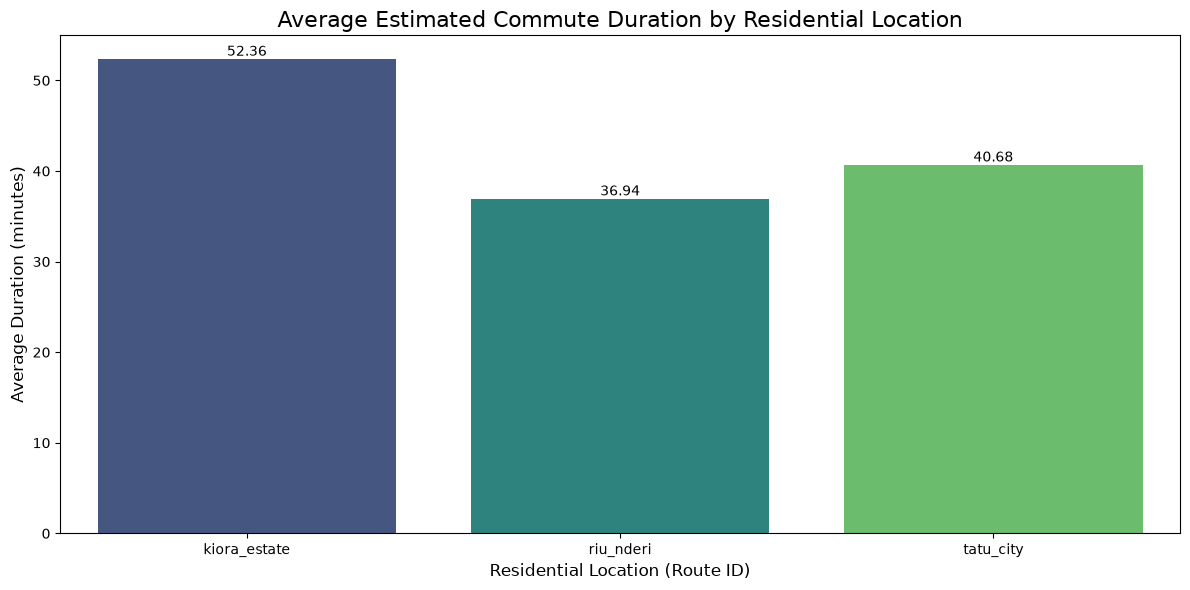

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns   

# Plot a bar chart

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=commute_summary,
    x="route_id",
    y="average_duration",
    palette="viridis"
)

# Add labels and title
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", label_type="edge", fontsize=10)

plt.title("Average Estimated Commute Duration by Residential Location", fontsize=16)
plt.xlabel("Residential Location (Route ID)", fontsize=12)
plt.ylabel("Average Duration (minutes)", fontsize=12)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


#### Finding 1: Average Commuting Efficiency

Riu Nderi recorded the shortest average estimated journey
duration (36.94 minutes), followed by Tatu City
(40.68 minutes) and Kiora Estate (52.36 minutes).

The difference between Riu Nderi and Kiora Estate
was 15.42 minutes per observed journey.

Across 22 comparable one-way commutes, this represents
approximately 5.65 hours of potential monthly time savings.

However, the calculation assumes that the observed
average differences are representative of future
commuting conditions. Further analysis by departure
period is required before making recommendations.


### 3.2 Morning versus Evening Commuting Patterns

In [ ]:
df.columns

Index(['observation_slot_eat', 'actual_request_time_eat', 'route_id', 'origin',
       'destination', 'status', 'duration_minutes', 'static_duration_minutes',
       'estimated_traffic_delay_minutes', 'distance_km', 'route_description',
       'route_steps', 'mode', 'routing_preference', 'observation_date',
       'departure_hour', 'departure_time', 'day_of_week', 'commute_period',
       'material_disruption'],
      dtype='str')

In [ ]:
# Compare average journey duration by location and period

period_summary = (
    df.groupby(["route_id", "commute_period"])
    ["duration_minutes"]
    .agg(
        observations="count",
        average_duration="mean",
        median_duration="median",
        std_duration="std"
    )
    .round(2)
    .reset_index()
)

display(period_summary)


,route_id,commute_period,observations,average_duration,median_duration,std_duration
0,kiora_estate,Evening,39,53.83,54.20,2.41
1,kiora_estate,Morning,39,50.88,51.82,4.46
2,riu_nderi,Evening,39,38.13,37.82,1.12
3,riu_nderi,Morning,39,35.74,35.75,1.48
4,tatu_city,Evening,39,37.06,35.45,5.58
5,tatu_city,Morning,39,44.31,44.82,5.18


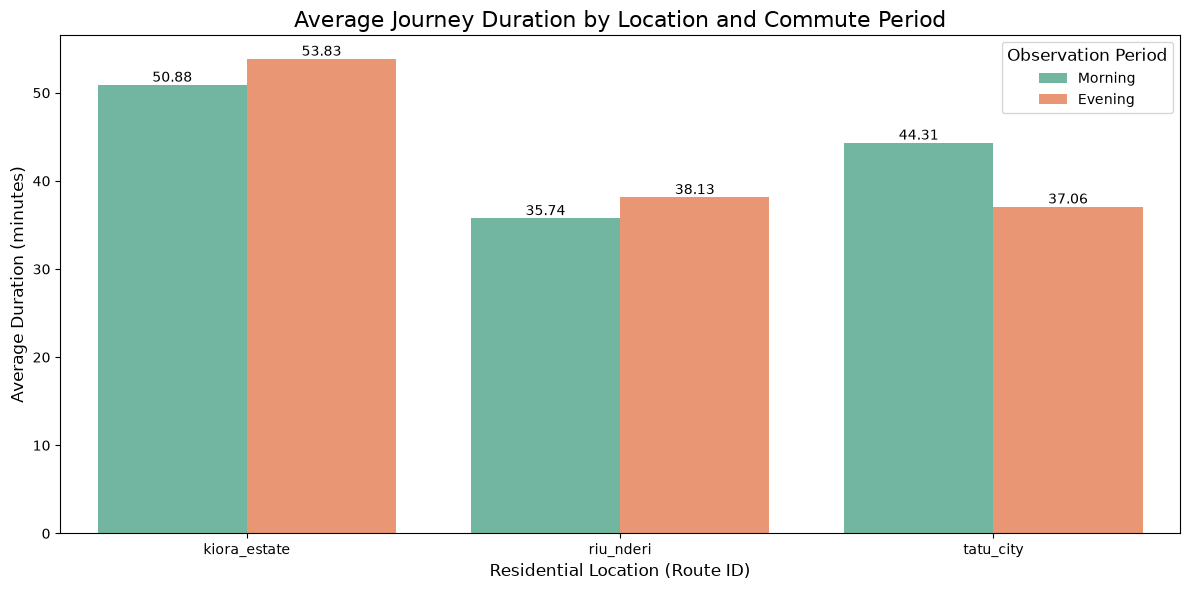

In [ ]:
# Compare morning & evening journey durations

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=period_summary,
    x="route_id",
    y="average_duration",
    hue="commute_period",
    hue_order=["Morning", "Evening"],
    palette="Set2"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", label_type="edge", fontsize=10)

plt.title("Average Journey Duration by Location and Commute Period", fontsize=16)
plt.xlabel("Residential Location (Route ID)", fontsize=12)
plt.ylabel("Average Duration (minutes)", fontsize=12)
plt.legend(title="Observation Period", title_fontsize=12, fontsize=10)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()




#### Finding 2: Morning and Evening Commuting Patterns

Riu Nderi recorded the shortest average morning journey
duration (35.74 minutes), followed by Tatu City
(44.31 minutes) and Kiora Estate (50.88 minutes).

Riu Nderi also recorded the lowest morning standard
deviation (1.48 minutes), suggesting more consistent
journey-time estimates during the observation period.

During the evening, Tatu City recorded the shortest
average journey duration (37.06 minutes), marginally
below Riu Nderi (38.13 minutes).

However, Riu Nderi maintained considerably lower
journey-time variability in the evening.

These findings are preliminary and reflect only
three days of traffic-aware driving estimates.

All recorded journeys were towards Westlands;
evening observations do not represent return commutes.


### 3.3 Journey Duration by Departure Time

Objective:
To investigate how estimated journey durations vary
across scheduled departure times for each location.

In [ ]:
df.columns

Index(['observation_slot_eat', 'actual_request_time_eat', 'route_id', 'origin',
       'destination', 'status', 'duration_minutes', 'static_duration_minutes',
       'estimated_traffic_delay_minutes', 'distance_km', 'route_description',
       'route_steps', 'mode', 'routing_preference', 'observation_date',
       'departure_hour', 'departure_time', 'day_of_week', 'commute_period',
       'material_disruption'],
      dtype='str')

In [ ]:
# Calculate average journey time by location & departure slot

departure_summary = (
    df.groupby(["route_id", "commute_period", "departure_time"])
    ["duration_minutes"]
    .agg(
        observations="count",
        average_duration="mean",
        minimum_duration="min",
        maximum_duration="max",
    )
    .round(2)
    .reset_index()
)

# Display morning observations
display(
    departure_summary.loc[
        departure_summary["commute_period"] == "Morning"
    ]
)

,route_id,commute_period,departure_time,observations,average_duration,minimum_duration,maximum_duration
13,kiora_estate,Morning,06:00,3,41.41,40.33,42.73
14,kiora_estate,Morning,06:15,3,44.69,42.30,45.90
15,kiora_estate,Morning,06:30,3,48.62,48.27,49.13
16,kiora_estate,Morning,06:45,3,51.94,51.82,52.05
17,kiora_estate,Morning,07:00,3,55.13,54.78,55.33
18,kiora_estate,Morning,07:15,3,54.28,53.57,55.67
19,kiora_estate,Morning,07:30,3,56.39,54.88,58.62
20,kiora_estate,Morning,07:45,3,55.02,53.78,56.08
21,kiora_estate,Morning,08:00,3,53.77,53.02,54.88
22,kiora_estate,Morning,08:15,3,52.67,49.65,55.58


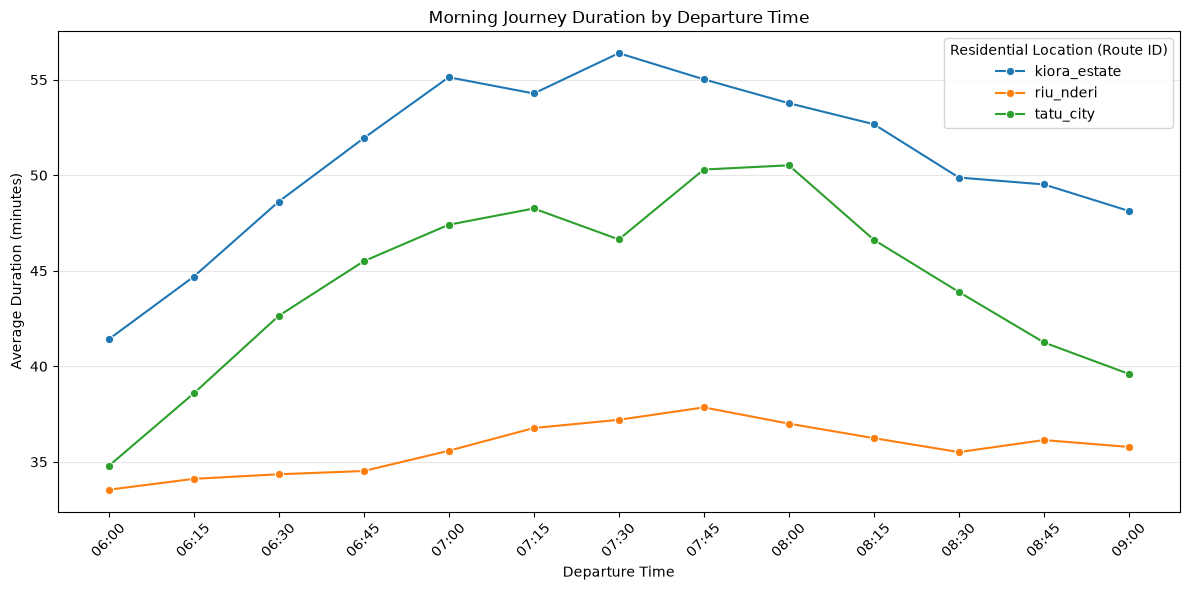

In [ ]:
# Filter to morning observations
morning_data = departure_summary[
    departure_summary["commute_period"] == "Morning"
]

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=morning_data,
    x="departure_time",
    y="average_duration",
    hue="route_id",
    marker="o"
)

plt.title("Morning Journey Duration by Departure Time")
plt.xlabel("Departure Time")
plt.ylabel("Average Duration (minutes)")
plt.xticks(rotation=45)
plt.legend(title="Residential Location (Route ID)")
plt.grid(axis="y",alpha=0.3)    

plt.tight_layout()
plt.show()


#### Finding 3: Morning Departure-Time Patterns

Riu Nderi recorded the shortest average estimated journey
duration across all 13 morning departure slots.

Its slot averages ranged from 33.54 to 37.85 minutes,
representing a difference of 4.31 minutes.

Kiora Estate recorded its highest average journey
duration at 7:30 AM (56.39 minutes), while Tatu City
peaked at 8:00 AM (50.52 minutes).

Riu Nderi recorded its highest slot average at
7:45 AM (37.85 minutes).

These findings suggest that Riu Nderi offered a more
consistent commuting experience during the observed
morning periods.

However, each departure slot contains only three
observations, limiting conclusions about long-term
commuting conditions.



### 3.4 Morning Commuting Reliability and Variability

Objective:
To assess and compare the predictability of morning
journey durations across the three residential locations
using standard deviation, P90 and other reliability metrics.


In [ ]:
# Calculating morning commute reliability metrics

morning_df = df[
    (df["commute_period"] == "Morning")
].copy()

reliability_summary = (
    morning_df.groupby("route_id")["duration_minutes"]
    .agg(
        observations="count",
        average_duration="mean",
        median_duration="median",
        std_duration="std",
        p90_duration=lambda x: x.quantile(0.9),
        maximum_duration="max"
    )
    .round(2)
    .reset_index()
)

display(reliability_summary)

,route_id,observations,average_duration,median_duration,std_duration,p90_duration,maximum_duration
0,kiora_estate,39,50.88,51.82,4.46,55.6,58.62
1,riu_nderi,39,35.74,35.75,1.48,37.4,39.75
2,tatu_city,39,44.31,44.82,5.18,50.8,55.30



#### Finding 4: Morning Commuting Reliability

Riu Nderi recorded the shortest average morning commute
(35.74 minutes) and the lowest standard deviation
(1.48 minutes), indicating greater consistency during
the observed period.

Its P90 journey duration was 37.40 minutes, compared
with 50.80 minutes for Tatu City and 55.60 minutes
for Kiora Estate.

Riu Nderi therefore demonstrated the strongest
combination of commuting efficiency and reliability
within the three-day observation period.

These findings remain preliminary due to the limited
collection period and variation in departure times.



### 3.5 Morning Journey-Time Distribution

Objective:
To visualise the distribution, variability and potential
outliers in morning journey durations across the three
residential locations.


C:\Users\Cyrus\AppData\Local\Temp\ipykernel_20800\34234768.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


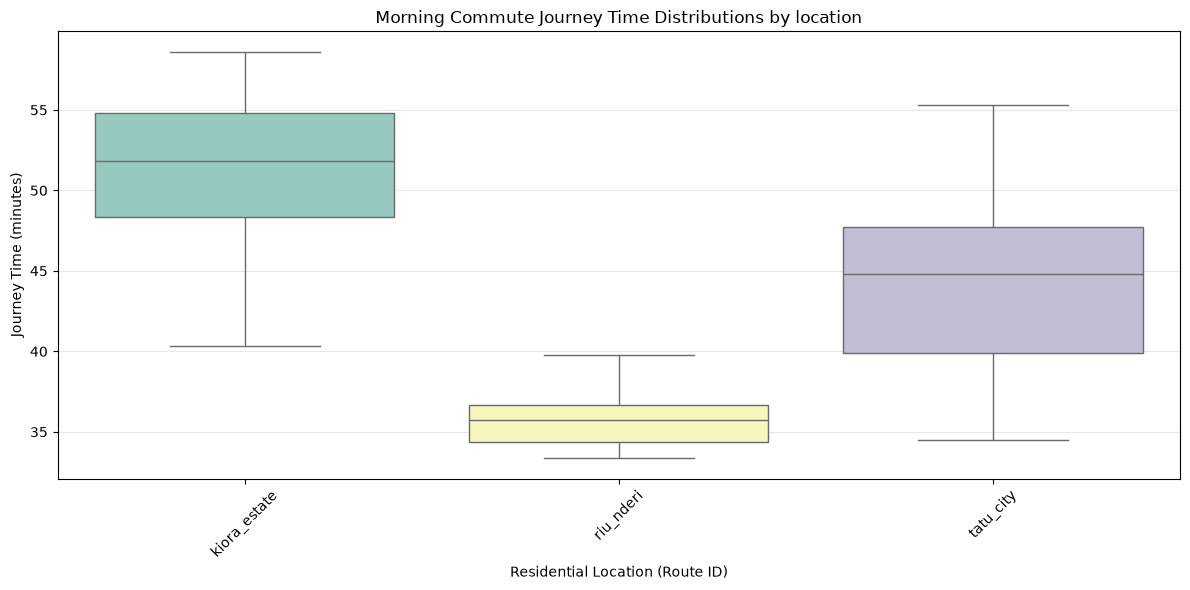

In [ ]:
# Visualize morning journey-time distributions

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=morning_df,
    x="route_id",
    y="duration_minutes",
    palette="Set3"
)
plt.xlabel("Residential Location (Route ID)")
plt.ylabel("Journey Time (minutes)")
plt.title("Morning Commute Journey Time Distributions by location")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


#### Finding 5: Morning Journey-Time Distribution

Riu Nderi exhibits the narrowest box plot, suggesting
lower variability in its morning journey durations.

This is consistent with its low standard deviation
of 1.48 minutes, compared with 4.46 minutes for
Kiora Estate and 5.18 minutes for Tatu City.

No potential outliers were identified visually
using the default box-plot criteria.

Overall, Riu Nderi demonstrates the most consistent
morning journey estimates during the observed period.



### 3.6 Morning Congestion and Material Disruption Analysis

Objective:
To compare estimated traffic-related delays and the
frequency of material disruptions across the three
residential locations during morning commuting hours.


In [ ]:
# Calculate morning traffic delay statistics
congestion_summary = (
    morning_df.groupby("route_id")
    .agg(
        obeservations=("route_id", "count"),
        average_duration=("duration_minutes", "mean"),
        average_static_duration=("static_duration_minutes", "mean"),
        average_traffic_delay=("estimated_traffic_delay_minutes", "mean"),
        maximum_traffic_delay=("estimated_traffic_delay_minutes", "max"),
        p90_traffic_delay=(
            "estimated_traffic_delay_minutes",
            lambda x: x.quantile(0.9)  
        )
    )
    .round(2)
    .reset_index()
)

display(congestion_summary)


,route_id,obeservations,average_duration,average_static_duration,average_traffic_delay,maximum_traffic_delay,p90_traffic_delay
0,kiora_estate,39,50.88,50.10,0.78,8.13,4.83
1,riu_nderi,39,35.74,36.97,-1.23,2.45,-0.08
2,tatu_city,39,44.31,37.72,6.59,16.23,14.17


C:\Users\Cyrus\AppData\Local\Temp\ipykernel_20800\425673925.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


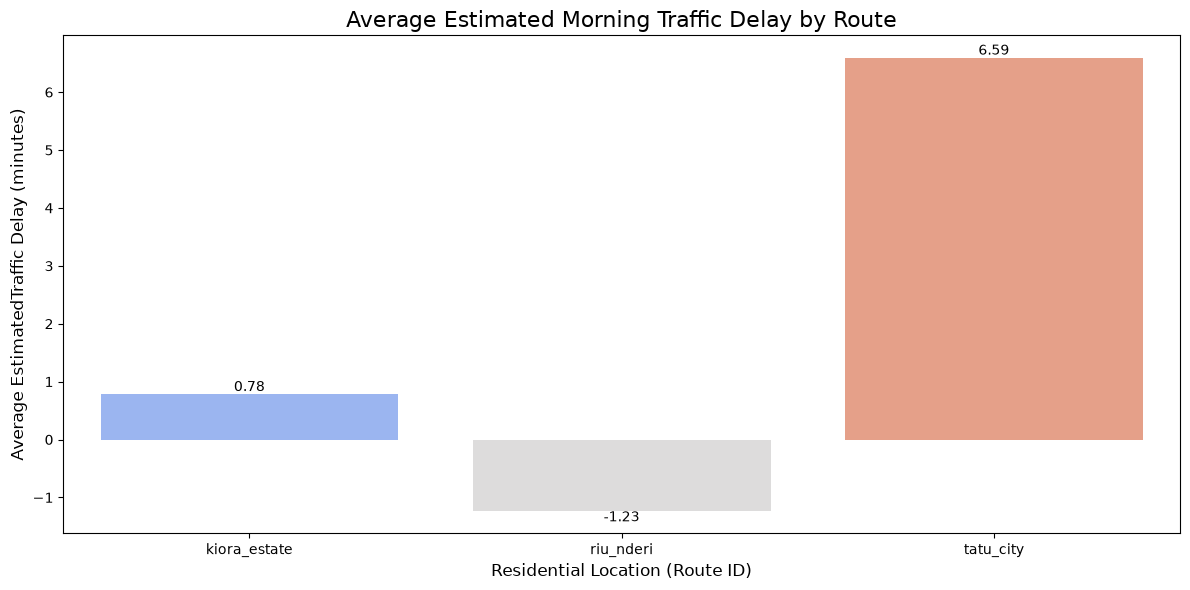

In [ ]:
# Compare estimated average traffic delays

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=congestion_summary,
    x="route_id",
    y="average_traffic_delay",
    palette="coolwarm"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", label_type="edge", fontsize=10)

plt.title("Average Estimated Morning Traffic Delay by Route", fontsize=16)
plt.xlabel("Residential Location (Route ID)", fontsize=12)
plt.ylabel("Average EstimatedTraffic Delay (minutes)", fontsize=12)

plt.tight_layout()
plt.show()


#### Finding 6: Morning Congestion Patterns

Tatu City recorded the highest average estimated
traffic adjustment (+6.59 minutes), with a P90
adjustment of 14.17 minutes.

Kiora Estate recorded a relatively small average
traffic adjustment (+0.78 minutes), suggesting its
longer journey durations are largely associated
with baseline route travel time.

Riu Nderi recorded a negative average traffic
adjustment (-1.23 minutes), indicating that its
traffic-aware estimates were generally shorter
than the static reference estimates.

These differences represent estimated traffic
adjustments rather than directly observed delays.



### 3.7 Summary of Morning Commuting Insights

Objective:
To consolidate the key findings from the exploratory
analysis and identify the strongest residential location
based on morning commuting efficiency and reliability.


In [ ]:
# Consolidated morning commute reliability

morning_performance = (
    morning_df.groupby("route_id")
    .agg(
        observations=("duration_minutes", "count"),
        average_duration=("duration_minutes", "mean"),
        median_duration=("duration_minutes", "median"),
        std_duration=("duration_minutes", "std"),
        p90_duration=("duration_minutes", lambda x: x.quantile(0.9)),
        average_traffic_adjustment=("estimated_traffic_delay_minutes", "mean")
        )
        .round(2)
        .reset_index()
)

display(morning_performance)

,route_id,observations,average_duration,median_duration,std_duration,p90_duration,average_traffic_adjustment
0,kiora_estate,39,50.88,51.82,4.46,55.6,0.78
1,riu_nderi,39,35.74,35.75,1.48,37.4,-1.23
2,tatu_city,39,44.31,44.82,5.18,50.8,6.59



#### EDA Summary

Riu Nderi demonstrated the strongest morning commuting
performance, recording the shortest average journey
duration (35.74 minutes), lowest standard deviation
(1.48 minutes), and lowest P90 duration (37.40 minutes).

Tatu City ranked second in average commuting efficiency
but exhibited greater journey-time variability and
higher estimated traffic-related adjustments.

Kiora Estate recorded the longest average morning
journey duration (50.88 minutes).

Overall, Riu Nderi emerges as the strongest preliminary
option based on morning commuting efficiency and
reliability.

These findings are based on three days of Google Maps
traffic estimates and should not be interpreted as
long-term commuting guarantees.



## 4. Decision Analysis

### 4.1 Selection of Decision Criteria

Objective:
To develop a weighted scoring model that compares
residential locations based on morning commuting
efficiency, reliability and journey-time variability.



### 4.2 Normalisation of Decision Criteria

Objective:
To convert commuting performance indicators into
comparable scores using min-max normalisation,
where 100 represents the best performance.

In [ ]:
# Create a seperate Dataframe for decsion scoring
decision_scores = morning_performance[
    [
        "route_id",
        "average_duration",
        "p90_duration",
        "std_duration"
    ]
].copy()

# Define a function for lower is better normalisation
def normalise_lower_better(series):
    minimum = series.min()
    maximum = series.max()

    if maximum == minimum:
        return pd.Series(100.0, index=series.index)

    return ((maximum - series) / (maximum - minimum)) * 100

# Normalise the three decision criteria
decision_scores["average_score"] = normalise_lower_better(
    decision_scores["average_duration"]
)

decision_scores["p90_score"] = normalise_lower_better(
    decision_scores["p90_duration"]
)

decision_scores["variability_score"] = normalise_lower_better(
    decision_scores["std_duration"]
)

display(decision_scores.round(2))



,route_id,average_duration,p90_duration,std_duration,average_score,p90_score,variability_score
0,kiora_estate,50.88,55.6,4.46,0.00,0.00,19.46
1,riu_nderi,35.74,37.4,1.48,100.00,100.00,100.00
2,tatu_city,44.31,50.8,5.18,43.39,26.37,0.00



### 4.3 Weighted Decision Scoring

Objective:
To calculate an overall commuting performance score
for each residential location using the selected
decision criteria and their respective weights.


In [ ]:

# Define the decision criteria weights
weights = {
    "average_score": 0.30,
    "p90_score": 0.45,
    "variability_score": 0.25
}

# Calculate the overall weighted score
decision_scores["weighted_score"] = (
    decision_scores["average_score"] * weights["average_score"]
    + decision_scores["p90_score"] * weights["p90_score"]
    + decision_scores["variability_score"] * weights["variability_score"]
)

# Rank locations from highest to lowest score
decision_ranking = (
    decision_scores.sort_values(
        by="weighted_score",
        ascending=False
    )
    .reset_index(drop=True)
)

# Assign ranking
decision_ranking["rank"] = decision_ranking.index + 1

display(
    decision_ranking[
        [
            "rank",
            "route_id",
            "average_score",
            "p90_score",
            "variability_score",
            "weighted_score"
        ]
    ].round(2)
)


,rank,route_id,average_score,p90_score,variability_score,weighted_score
0,1,riu_nderi,100.00,100.00,100.00,100.00
1,2,tatu_city,43.39,26.37,0.00,24.89
2,3,kiora_estate,0.00,0.00,19.46,4.86


C:\Users\Cyrus\AppData\Local\Temp\ipykernel_20800\507179438.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


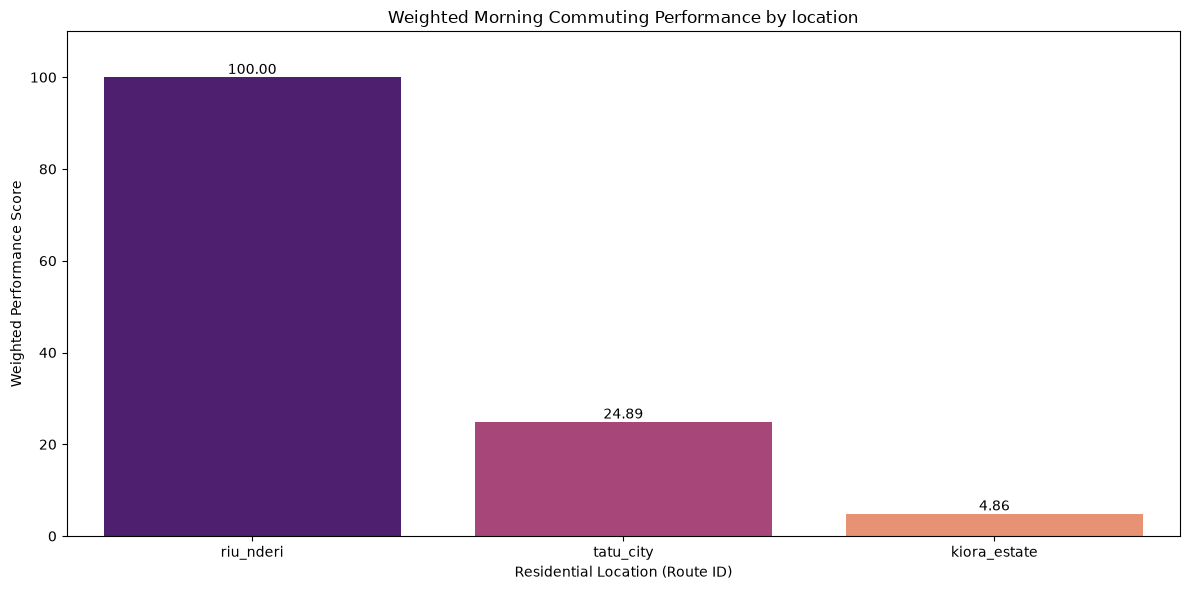

In [ ]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=decision_ranking,
    x="route_id",
    y="weighted_score",
    palette="magma"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", label_type="edge", fontsize=10)

plt.title("Weighted Morning Commuting Performance by location")
plt.xlabel("Residential Location (Route ID)")
plt.ylabel("Weighted Performance Score")
plt.ylim(0, 110)

plt.tight_layout()
plt.show()


#### Finding 7: Weighted Decision Rankings

Riu Nderi ranked first with a weighted score of
100.00, followed by Tatu City (24.89) and
Kiora Estate (4.86).

Riu Nderi performed best across all three criteria:
average journey duration, P90 duration and
standard deviation.

The results indicate that Riu Nderi is the
strongest option based on the selected morning
commuting criteria and available observations.

The scores are relative to the locations assessed
and do not represent absolute commuting quality.



### 4.4 Sensitivity Analysis

Objective:
To assess whether changes in decision criteria
weights materially affect the residential location
rankings.


In [ ]:

# Define alternative weighting scenarios

scenarios = {
    "Balanced": {
        "average_score": 0.3333,
        "p90_score": 0.3333,
        "variability_score": 0.3334
    },
    "Efficiency-focused": {
        "average_score": 0.60,
        "p90_score": 0.25,
        "variability_score": 0.15
    },
    "Reliability-focused": {
        "average_score": 0.15,
        "p90_score": 0.55,
        "variability_score": 0.30
    }
}

# Create a new table for sensitivity analysis
sensitivity_results = decision_scores[["route_id"]].copy()

# Calculate the weighted score under each scenario
for scenario_name, scenario_weights in scenarios.items():
    sensitivity_results[scenario_name] = sum(
        decision_scores[criterion] * weight
        for criterion, weight in scenario_weights.items()
    )

display(sensitivity_results.round(2))


,route_id,Balanced,Efficiency-focused,Reliability-focused
0,kiora_estate,6.49,2.92,5.84
1,riu_nderi,100.00,100.00,100.00
2,tatu_city,23.25,32.63,21.01


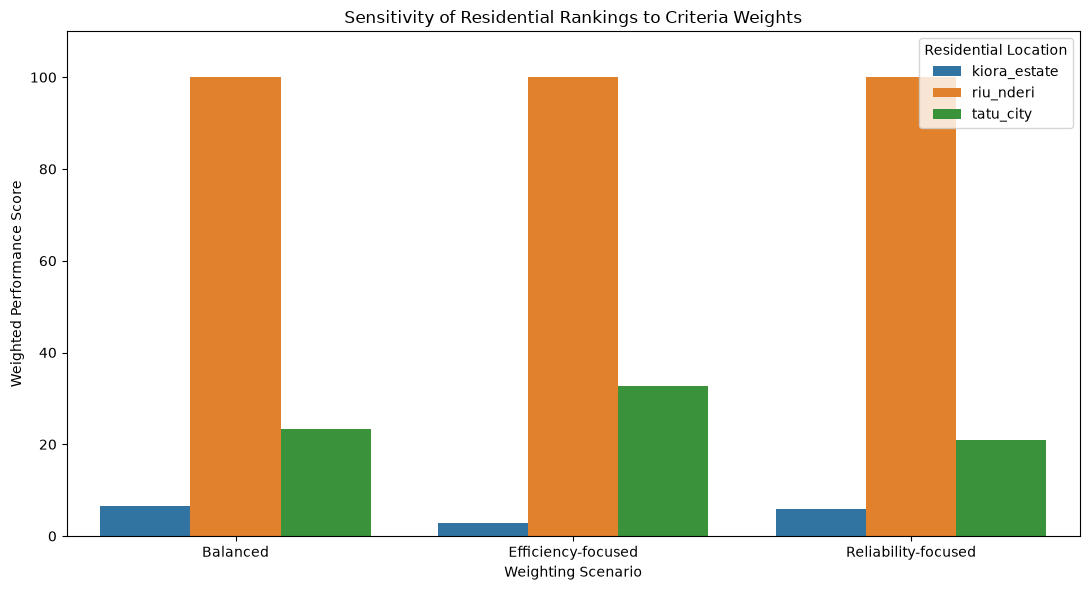

In [ ]:

# Convert scenario results to long format for plotting

sensitivity_long = sensitivity_results.melt(
    id_vars="route_id",
    var_name="scenario",
    value_name="weighted_score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=sensitivity_long,
    x="scenario",
    y="weighted_score",
    hue="route_id"
)

plt.title("Sensitivity of Residential Rankings to Criteria Weights")
plt.xlabel("Weighting Scenario")
plt.ylabel("Weighted Performance Score")
plt.ylim(0, 110)
plt.legend(title="Residential Location")

plt.tight_layout()
plt.show()



#### Finding 8: Sensitivity Analysis

Riu Nderi ranked first across all three weighting
scenarios, maintaining a score of 100.00.

Tatu City consistently ranked second, followed
by Kiora Estate.

The results indicate that the residential rankings
are robust across the tested weighting scenarios.

However, the findings remain dependent on the
selected criteria, available observations, and
normalisation methodology.



### 4.5 Decision Analysis Conclusion

Based on the observed morning commuting estimates,
Riu Nderi emerges as the strongest residential
location among the three alternatives.

It recorded the shortest average journey duration,
lowest P90 journey duration, and lowest standard
deviation.

The weighted decision model and sensitivity analysis
consistently ranked Riu Nderi first.

Tatu City ranked second, while Kiora Estate ranked
third under the tested scenarios.

Other material considerations include affordability,
security, neighbourhood characteristics, infrastructure,
and proximity to schools, hospitals, shopping centres
and recreational amenities.

The findings should therefore inform, rather than
determine, the final residential investment decision.



## 5. Conclusions and Recommendations

### 5.1 Executive Summary

This project evaluated morning commuting conditions
from three prospective residential locations in
Kiambu County—Kiora Estate, Riu Nderi and Tatu City—
to Westlands, Nairobi.

The analysis used 117 morning observations collected
between 4 and 6 November 2026 using Google Maps
traffic-aware journey estimates.

Riu Nderi emerged as the strongest location based
on commuting efficiency and reliability, recording
the shortest average journey duration (35.74 minutes),
lowest P90 duration (37.40 minutes) and lowest
standard deviation (1.48 minutes).

A weighted decision model and sensitivity analysis
consistently ranked Riu Nderi first among the three
alternatives.



### 5.2 Key Findings

**Commuting Efficiency**

Riu Nderi recorded the shortest average morning
journey (35.74 minutes), followed by Tatu City
(44.31 minutes) and Kiora Estate (50.88 minutes).

**Commuting Reliability**

Riu Nderi demonstrated the lowest journey-time
variability, with a standard deviation of 1.48 minutes
and a P90 duration of 37.40 minutes.

**Traffic Conditions**

Tatu City recorded the highest average estimated
traffic adjustment (+6.59 minutes), compared with
Kiora Estate (+0.78 minutes) and Riu Nderi
(-1.23 minutes).

**Decision Analysis**

Riu Nderi ranked first under the baseline weighted
model and all three alternative weighting scenarios.



### 5.3 Recommendations

**Primary Recommendation: Riu Nderi**

Prioritise Riu Nderi for further residential
evaluation, given its shorter and more consistent
estimated morning commute to Westlands.

**Secondary Alternative: Tatu City**

Consider Tatu City as an alternative, particularly
if its housing affordability, infrastructure or
other residential characteristics offer meaningful
advantages.

**Further Validation**

Collect additional traffic observations across
multiple weeks and conduct representative real-world
journeys before making a long-term property decision.

**Broader Residential Assessment**

Complement commuting findings with land prices,
infrastructure, security, access to amenities and
other household priorities.



### 5.4 Limitations

- The dataset covers only three days of observations.
- Journey durations are Google Maps estimates rather
  than actual recorded driving times.
- The analysis focuses on morning travel towards
  Westlands and excludes return journeys.
- Reliability estimates may be affected by the
  limited sample and differing departure times.
- The weighted scoring model reflects selected
  decision criteria and subjective weights.
- Housing affordability and other residential factors
  were not included in the quantitative assessment.

The findings should therefore be treated as
preliminary evidence to support further evaluation.


In [ ]:
# Export the final commuting decision rankings

from pathlib import Path

tables_dir = project_dir / "outputs" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

ranking_file = tables_dir / "morning_commute_rankings.csv"

decision_ranking.to_csv(ranking_file, index=False)

print(f"Decision rankings exported to:{ranking_file}")

Decision rankings exported to:c:\Users\Cyrus\Desktop\Data Analysis Projects\Project 2-Nairobi_Commute_Analysis\outputs\tables\morning_commute_rankings.csv


In [ ]:
# Export sensitivity anaysis results for Power BI

sensitivity_file = tables_dir / "sensitivity_analysis.csv"

sensitivity_results.to_csv(
    sensitivity_file,
    index=False
)

print(f"sensitivity analysis exported to: {sensitivity_file}")

sensitivity analysis exported to: c:\Users\Cyrus\Desktop\Data Analysis Projects\Project 2-Nairobi_Commute_Analysis\outputs\tables\sensitivity_analysis.csv
